🧠 Block 1: Data Ingestion & Feature Extraction

In traditional portfolio management, stocks are categorized by sector (Tech, Healthcare, Banking). In Factor Investing, we group stocks based on their quantitative behavioral characteristics:Annualized Volatility (Risk Factor): Measures the dispersion of daily returns scaled to a yearly calendar: $$\sigma_{\text{annual}} = \sigma_{\text{daily}} \times \sqrt{252}
$$Momentum (Trend Factor): Measures the total cumulative return over the analyzed timeframe to evaluate trend strength: $$\text{Momentum} = \frac{\text{Ending Price}}{\text{Starting Price}} - 1$$Sharpe Ratio (Efficiency Factor): Measures return per unit of risk taken (assuming a 0% risk-free rate for simplicity): $$\text{Sharpe Ratio} = \frac{\text{Mean Annualized Return}}{\sigma_{\text{annual}}}$$

In [ ]:
# ==============================================================================
# BLOCK 1: Data Ingestion & Quantitative Feature Extraction (Fixed)
# ==============================================================================

import numpy as np
import pandas as pd
import yfinance as yf

# 1. Define a diversified universe of S&P 500 tickers
tickers = [
    '^GSPC', 'AAPL', 'MSFT', 'NVDA', 'AMZN', 'GOOGL', 'META', 'TSLA', # Tech & Growth
    'JPM', 'BAC', 'V',                                               # Financials
    'JNJ', 'PFE', 'UNH',                                            # Healthcare
    'XOM', 'CVX',                                                   # Energy
    'PG', 'KO', 'PEP', 'WMT', 'HD'                                  # Consumer Staples / Defensive
]

print("📥 Downloading market data from Yahoo Finance...")
print()
# Adding auto_adjust=False preserves the 'Adj Close' column
df = yf.download(tickers, start="2023-01-01", end="2024-10-01", progress=False, auto_adjust=False)['Adj Close']
df = df.dropna()

# 2. Compute continuously compounded daily log returns
daily_returns = np.log(df / df.shift(1)).dropna()

# 3. Extract Quantitative Factors
volatility = daily_returns.std() * np.sqrt(252)                       # Risk factor
momentum = (df.iloc[-1] / df.iloc[0]) - 1                             # Trend factor (Total cumulative return)
sharpe_ratio = (daily_returns.mean() * 252) / volatility              # Efficiency factor

# 4. Consolidate into a Factors DataFrame
factors_df = pd.DataFrame({
    'Volatility': volatility,
    'Momentum': momentum,
    'Sharpe_Ratio': sharpe_ratio
})

print("✅ Factors calculated successfully! Sample output:")
print(factors_df.head(10).round(4))

📥 Downloading market data from Yahoo Finance...

✅ Factors calculated successfully! Sample output:
        Volatility  Momentum  Sharpe_Ratio
Ticker                                    
AAPL        0.2178    0.8805        1.6721
AMZN        0.3077    1.1712        1.4530
BAC         0.2478    0.2451        0.5102
CVX         0.2154   -0.0917       -0.2575
GOOGL       0.2927    0.8656        1.2287
HD          0.2112    0.3436        0.8063
JNJ         0.1611   -0.0410       -0.1497
JPM         0.2069    0.6354        1.3709
KO          0.1295    0.2044        0.8282
META        0.3824    3.6029        2.3025


🧠 Block 2 Theory: Why do we need StandardScaler?

Algorithms like K-Means Clustering group stocks by calculating the Euclidean distance between them in multi-dimensional space:$$d(p, q) = \sqrt{(p_1 - q_1)^2 + (p_2 - q_2)^2 + (p_3 - q_3)^2}$$

Look at the raw numbers from Block 1:Volatility values usually range between 0.15 and 0.45 (15% to 45%).Sharpe Ratios might range between -0.5 and 2.5.Momentum returns can range between -0.20 and 1.50 (or higher for high-growth tech).If we pass raw features directly to K-Means, the feature with the largest numerical scale or spread will dominate the distance calculation, making the smaller-scale features virtually invisible to the model.StandardScaler transforms each feature so that it has a mean of 0 ($\mu = 0$) and a standard deviation of 1 ($\sigma = 1$):$$Z = \frac{X - \mu}{\sigma}$$

This puts Volatility, Momentum, and Sharpe Ratio on an equal playing field.

In [ ]:
# ==============================================================================
# BLOCK 2: Feature Scaling using StandardScaler
# ==============================================================================

from sklearn.preprocessing import StandardScaler

# 1. Initialize the scaler
scaler = StandardScaler()

# 2. Fit and transform the financial factors
scaled_factors = scaler.fit_transform(factors_df)

# 3. Reconstruct as a clean pandas DataFrame
scaled_df = pd.DataFrame(
    scaled_factors,
    columns=factors_df.columns,
    index=factors_df.index
)

print("✅ Features scaled successfully!")
print("\nSample of Scaled Factors (Z-scores):")
print(scaled_df.head(10).round(4))

print("\nVerification - Mean of scaled features (Should be ~0):")
print(scaled_df.mean().round(4))

print("\nVerification - Standard Deviation of scaled features (Should be ~1):")
print(scaled_df.std().round(4))

✅ Features scaled successfully!

Sample of Scaled Factors (Z-scores):
        Volatility  Momentum  Sharpe_Ratio
Ticker                                    
AAPL       -0.2279   -0.0219        0.8379
AMZN        0.5871    0.1518        0.5885
BAC         0.0443   -0.4017       -0.4849
CVX        -0.2500   -0.6031       -1.3588
GOOGL       0.4511   -0.0308        0.3331
HD         -0.2875   -0.3429       -0.1478
JNJ        -0.7419   -0.5728       -1.2361
JPM        -0.3266   -0.1684        0.4950
KO         -1.0286   -0.4261       -0.1228
META        1.2643    1.6055        1.5555

Verification - Mean of scaled features (Should be ~0):
Volatility      0.0
Momentum        0.0
Sharpe_Ratio    0.0
dtype: float64

Verification - Standard Deviation of scaled features (Should be ~1):
Volatility      1.0247
Momentum        1.0247
Sharpe_Ratio    1.0247
dtype: float64


🧠 Block 3 Theory: How K-Means & The Elbow Method Work
1. **What is K-Means Clustering?** K-Means is an unsupervised machine learning algorithm that partitions $N$ data points (our stocks) into $K$ distinct clusters based on feature proximity.

*   It places $K$ random points called centroids.
*   It assigns each stock to its nearest centroid using Euclidean distance.
*   It iteratively recalculates centroid positions until the clusters stabilize.

2. **How do we choose the optimal number of clusters ($K$)?** We use the *Elbow Method*:

*   We run K-Means for a range of cluster values (e.g., $K = 1$ to $7$).
*   For each $K$, we calculate Inertia (the Sum of Squared Distances from each stock to its assigned cluster centroid).

*   As $K$ increases, inertia naturally decreases. We look for the "elbow" point on the plot—the point where adding another cluster yields diminishing returns in error reduction.
*   In financial factor investing, $K=3$ often represents three distinct market profiles: High Risk / Growth, Defensive / Value, and Balanced / Quality.


In [ ]:
# ==============================================================================
# BLOCK 3: Optimal K Selection (Elbow Method) & K-Means Fitting
# ==============================================================================

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. Compute Inertia for K ranging from 1 to 7
inertias = []
K_range = range(1, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_factors)
    inertias.append(kmeans.inertia_)

# 2. Fit K-Means with the chosen optimal K = 3
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)

# Assign cluster labels to the original factors DataFrame
factors_df['Cluster'] = kmeans.fit_predict(scaled_factors)

print(f"✅ K-Means fitted successfully with K = {optimal_k} clusters!\n")

# 3. Analyze the Average Financial Profile per Cluster
cluster_profiles = factors_df.groupby('Cluster')[['Volatility', 'Momentum', 'Sharpe_Ratio']].mean()
print("📊 Average Factor Values per Cluster:")
print(cluster_profiles.round(4))

# Count how many stocks fall into each cluster
print("\n📈 Stock Count per Cluster:")
print(factors_df['Cluster'].value_counts().sort_index())

✅ K-Means fitted successfully with K = 3 clusters!

📊 Average Factor Values per Cluster:
         Volatility  Momentum  Sharpe_Ratio
Cluster                                    
0            0.2090    0.0074       -0.0491
1            0.4796    4.1707        1.8842
2            0.2000    0.6088        1.3044

📈 Stock Count per Cluster:
Cluster
0     7
1     3
2    11
Name: count, dtype: int64


🧠 Block 4 Theory: Why do we need PCA (Principal Component Analysis)?

Right now, our dataset has 3 features (Volatility, Momentum, Sharpe_Ratio). That means our stocks exist in a 3D space. While 3D plots exist, they are often difficult to read, print, or share on LinkedIn/GitHub.
PCA (Principal Component Analysis) solves this problem:

1.   It calculates new, uncorrelated axes called *Principal Components *(PC1, PC2, ...).
2.   PC1 captures the direction of maximum variance (spread) in the data.
3. PC2 captures the second largest variance perpendicular (orthogonal) to PC1.
4. By projecting our 3 factors onto PC1 and PC2, we reduce dimensions from 3D to 2D while keeping ~85–95% of the total variance!

✅ PCA complete! Total variance preserved in 2D: 94.01%
   - PC1: 71.92% | PC2: 22.09%



/tmp/ipykernel_1438/3064104570.py:27: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "bo-" (-> color='b'). The keyword argument will take precedence.
  ax1.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8, color='#1f77b4')


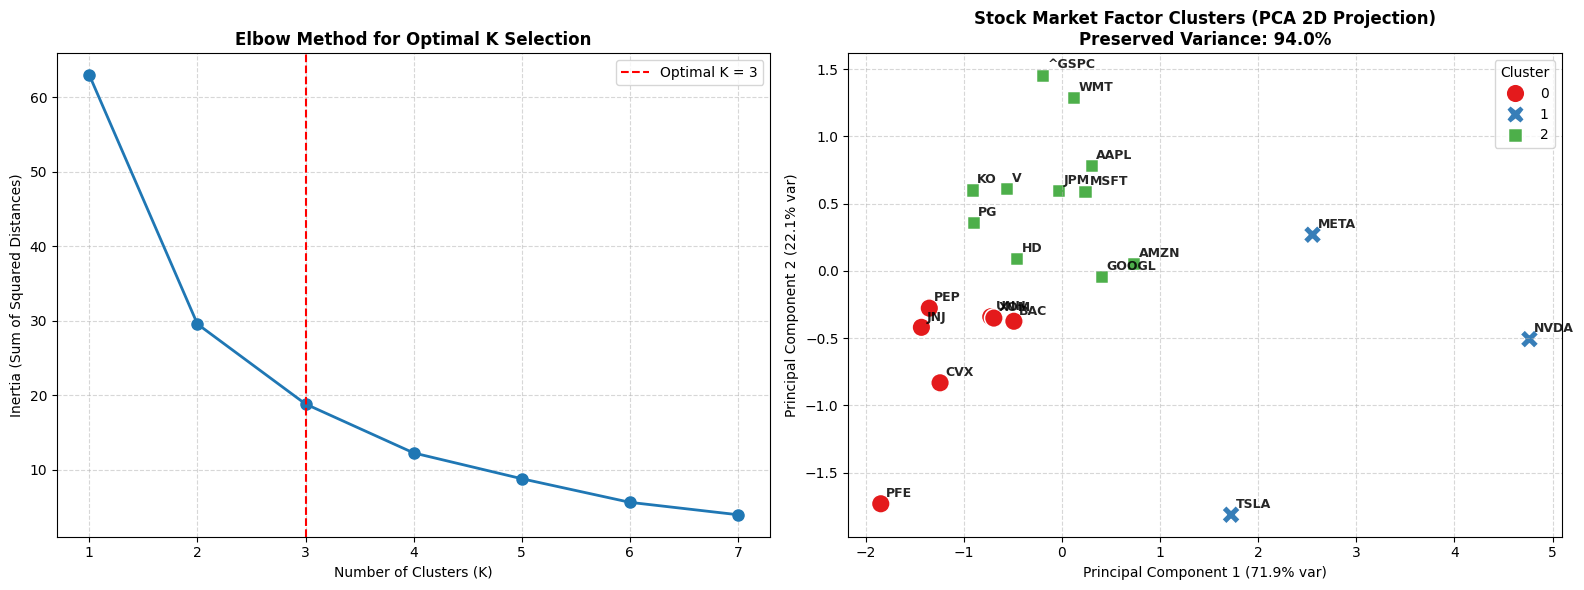

In [ ]:
# ==============================================================================
# BLOCK 4: PCA Reduction & Complete Visual Dashboard
# ==============================================================================

import seaborn as sns
from sklearn.decomposition import PCA

# 1. Apply PCA to reduce scaled factors to 2 Principal Components
pca = PCA(n_components=2)
pca_components = pca.fit_transform(scaled_factors)

# Store PCs in our main DataFrame
factors_df['PC1'] = pca_components[:, 0]
factors_df['PC2'] = pca_components[:, 1]

# Calculate variance explained by each component
explained_var = pca.explained_variance_ratio_ * 100
total_explained = explained_var.sum()

print(f"✅ PCA complete! Total variance preserved in 2D: {total_explained:.2f}%")
print(f"   - PC1: {explained_var[0]:.2f}% | PC2: {explained_var[1]:.2f}%\n")

# 2. Plotting Dashboard (Elbow Curve + PCA Scatter Plot)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Elbow Curve
ax1.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8, color='#1f77b4')
ax1.axvline(x=optimal_k, color='red', linestyle='--', label=f'Optimal K = {optimal_k}')
ax1.set_title('Elbow Method for Optimal K Selection', fontsize=12, fontweight='bold')
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia (Sum of Squared Distances)')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Subplot 2: 2D Cluster Projection via PCA
palette = sns.color_palette("Set1", optimal_k)
sns.scatterplot(
    data=factors_df, x='PC1', y='PC2', hue='Cluster',
    style='Cluster', s=180, palette=palette, ax=ax2
)

# Annotate each point with its stock ticker
for ticker in factors_df.index:
    ax2.annotate(
        ticker,
        (factors_df.loc[ticker, 'PC1'] + 0.05, factors_df.loc[ticker, 'PC2'] + 0.05),
        fontsize=9, fontweight='bold', alpha=0.85
    )

ax2.set_title(
    f'Stock Market Factor Clusters (PCA 2D Projection)\nPreserved Variance: {total_explained:.1f}%',
    fontsize=12, fontweight='bold'
)
ax2.set_xlabel(f'Principal Component 1 ({explained_var[0]:.1f}% var)')
ax2.set_ylabel(f'Principal Component 2 ({explained_var[1]:.1f}% var)')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()